### Лабораторная работа №1. Иерархический кластерный анализ

Тема: Кластеризация городов по экономическим показателям.

Данные описывают экономические условия в 48 городах мира в 1991 году.

Данные были собраны отделом экономических исследований банка Union (Швейцария). Описаны экономические условия в 48 городах мира в 1991 году.

Число наблюдений: 48
Названия переменных:
- City (Город): Название города
- Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12 профессиям
- Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за жилье (значение для Цюриха взято за 100%)
- Заработная плата (Salary): Индекс заработной платы за час работы, сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха взято за 100%)

In [ ]:
#  Активируем библиотеки

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

In [2]:
# Загружаем данные об экономике городов

df = pd.read_csv("Econom_Cities_data.csv", 
                 sep=";", 
                 decimal=",",  # Дробные числа записаны через запятую
                 index_col="City"  # Названия городов будут индексами таблицы
                 ) 

In [3]:
df.head()

,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5
Bombay,2052,30.3,5.3
Brussels,1708,73.8,50.5


Перед кластеризацией нужно убедиться, что в таблице нет пропусков и некорректных значений

In [4]:
# Проверяем размер таблицы
print("Размер таблицы:", df.shape)

# Смотрим типы данных и наличие пропусков
df.info()

# Выводим основные статистические показатели
df.describe()

Размер таблицы: (48, 3)
<class 'pandas.DataFrame'>
Index: 48 entries, Amsterdam to Zurich
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Work    48 non-null     int64  
 1   Price   48 non-null     float64
 2   Salary  48 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 1.5+ KB


,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


Пропусков значений мы не видим, 

In [5]:
# Ищем города со значением -9999 по всем столбцам
df[(df == -9999).any(axis=1)]

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


Для городов Cairo и Jakarta отсутствуют 2 из 3 признаков. Восстановление значений может исказить результаты кластеризации, поэтому принято решение удалить эти строки.

In [6]:
# Заменяем значение -9999 на NaN
df_clean = df.replace(-9999, np.nan)

# Удаляем города с пропущенными данными (Cairo и Jakarta)
df_clean = df_clean.dropna()

# Сравниваем размеры таблицы до/после очистки
print("До очистки: ", df.shape)
print("После очистки: ", df_clean.shape)

До очистки:  (48, 3)
После очистки:  (46, 3)


Видим, что 2 города удалилось

In [7]:
# Смотрим обновленную статистику
df_clean.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


Поскольку признаки в датасете имеют разные масштабы, необходимо выполнить стандартизацию.  
Для этого выбран метод StandardScaler, который приводит каждый признак к нулевому среднему и единичной дисперсии.  
Это позволяет исключить влияние масштаба признаков на результаты кластеризации.

In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
# Создаём объект стандартизации
scaler = StandardScaler()

# Вычисляем среднее и стандартное отклонение
scaler.fit(df_clean)

# Стандартизуем данные и сохраняем в X_scaled
X_scaled = pd.DataFrame(
    scaler.transform(df_clean),
    columns=df_clean.columns,  # Возвращаем название столбцов
    index=df_clean.index  # Возвращаем название городов
)

X_scaled.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351


Переходим к кластерному анализу.  
Используем метод Уорда, который объединяет похожие города в компактные и однородные группы, стараясь минимизировать различия внутри кластеров.

In [10]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score

In [11]:
# Выполняем иерархическую кластеризацию
link = linkage(X_scaled, 'ward', 'euclidean')

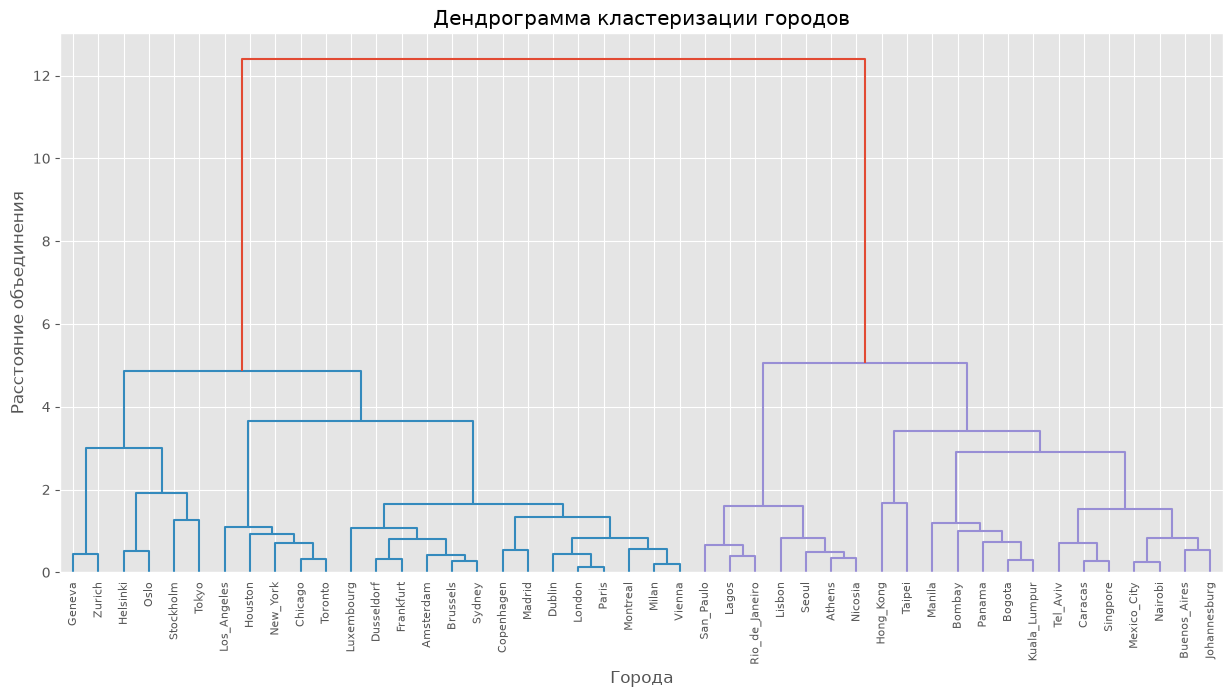

In [12]:
# Строим дендрограмму
plt.figure(figsize=(15,7))

dendrogram(
    link,
    labels=X_scaled.index,
    leaf_rotation=90,
)

plt.title("Дендрограмма кластеризации городов")
plt.xlabel("Города")
plt.ylabel("Расстояние объединения")
plt.show()

По дендрограмме метода Уорда видно, что города разделяются на 2 основные группы. Последнее объединение происходит на расстоянии около 12,5, тогда как предыдущие ~5.

Такой большой скачок позволяет предварительно выбрать 2 кластера. Для проверки этого решения рассчитаем коэффициент силуэта.

Коэффициент силуэта (Silhouette Score) показывает, насколько хорошо объекты распределены по кластерам.
- Ближе к 1 — кластеры хорошо разделены.
- Около 0 — группы пересекаются.
- Ниже 0 — некоторые объекты могут быть отнесены не к своей группе.

In [13]:
from sklearn.metrics import silhouette_score

In [14]:
# Проверяем от 2 до 6 кластеров
for k in range(2, 7):
    # Разделяем города на k кластеров методом Уорда
    clusters = fcluster(link, k, criterion='maxclust')
    # Расчитываем коэф. силуэта
    score = silhouette_score(X_scaled, clusters)
    
    print(f"Кластеров {k}, коэф. силуэта {score:.3f}")

Кластеров 2, коэф. силуэта 0.470
Кластеров 3, коэф. силуэта 0.361
Кластеров 4, коэф. силуэта 0.355
Кластеров 5, коэф. силуэта 0.348
Кластеров 6, коэф. силуэта 0.366


Наибольшее значение 0,470 получено при разделении на 2 кластера. Это подтверждает вывод, сделанный по дендрограмме.  
Поэтому для дальнейшего анализа выбираем 2 кластера.

Следующим шагом определяем, какие города попали в каждый из 2х кластеров

In [15]:
# Разделим города на 2 кластера
clusters = fcluster(link, 2, criterion='maxclust')

# Добавляем номер кластера к исходным данным
df_result = df_clean.copy()
df_result['Cluster'] = clusters

# Смотрим распределение городов
df_result.sort_values('Cluster')

,Work,Price,Salary,Cluster
City,,,,
Amsterdam,1714.0,65.6,49.0,1
Brussels,1708.0,73.8,50.5,1
Chicago,1924.0,73.9,61.9,1
Geneva,1880.0,95.9,90.3,1
Frankfurt,1650.0,74.5,60.4,1
Dusseldorf,1693.0,78.5,60.2,1
Dublin,1759.0,76.0,41.4,1
Copenhagen,1717.0,91.3,62.9,1
Houston,1978.0,71.9,46.3,1


In [16]:
# Считаем кол-во городов в каждом кластере
df_result['Cluster'].value_counts()

Cluster
1    25
2    21
Name: count, dtype: int64

В первом кластере получилось 25 городов  
Во втором 21 город

In [17]:
# Рассчитываем средние экономические показатели по кластерам
df_result.groupby('Cluster')[['Work', 'Price', 'Salary']].mean().round(2)

,Work,Price,Salary
Cluster,,,
1,1789.24,84.97,59.03
2,1987.86,52.40,16.35


Кластер 1: города с более высокими зарплатами и ценами, но меньшим количеством рабочих часов  
Кластер 2: города с более низкими зарплатами и ценами, но большим количеством рабочих часов

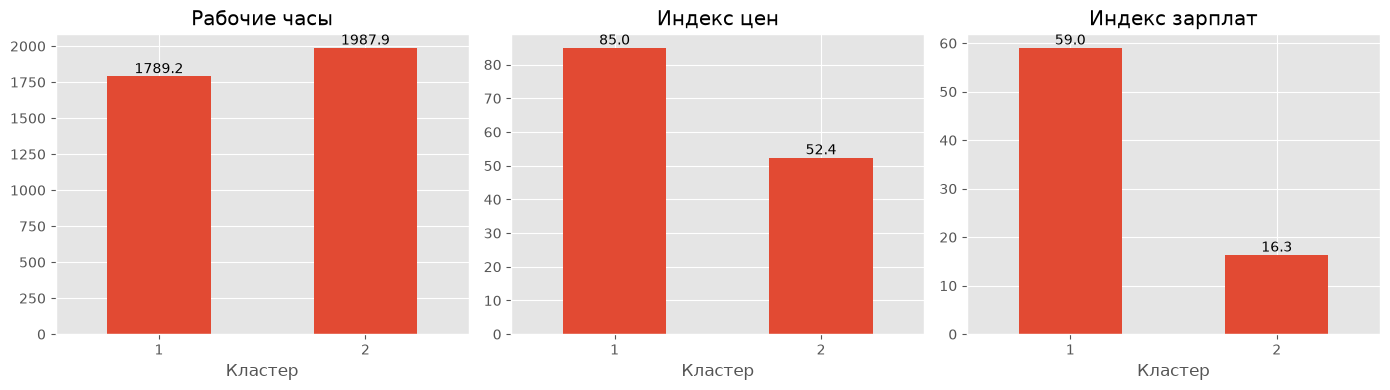

In [18]:
# Рассчитываем средние значения по кластерам
cluster_means = df_result.groupby('Cluster')[['Work', 'Price', 'Salary']].mean()

# Создаём три графика
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

features = ['Work', 'Price', 'Salary']
titles = ['Рабочие часы', 'Индекс цен', 'Индекс зарплат']

for ax, feature, title in zip(axes, features, titles):
    cluster_means[feature].plot(kind='bar', ax=ax)

    ax.set_title(title)
    ax.set_xlabel('Кластер')
    ax.tick_params(axis='x', rotation=0)

    # Подписываем значения на столбцах
    ax.bar_label(ax.containers[0], fmt='%.1f')

plt.tight_layout()
plt.show()

## Выводы

В ходе лабораторной работы был проведён иерархический кластерный анализ экономических показателей 46 городов мира методом Уорда.

На основании дендрограммы и коэффициента силуэта 0,470 было выбрано 2 кластера:

Кластер 1 (25 городов) — более высокие зарплаты и цены, меньшее количество рабочих часов.

Кластер 2 (21 город) — более низкие зарплаты и цены, большее количество рабочих часов.

Наиболее заметные различия между группами наблюдаются в уровне заработной платы

А что если рассмотреть другие методы и расстояния?

In [19]:
# Функция иерархической кластеризации
def hierarchical_clustering(data, method='ward', n_clusters=2, metric='euclidean'):

    # Метод Уорда работает только с евклидовым расстоянием
    if method == 'ward' and metric != 'euclidean':
        raise ValueError("Метод Ward требует евклидово расстояние")

    # Выполняем кластеризацию
    link = linkage(data, method=method, metric=metric)

    # Разделяем объекты на кластеры
    clusters = fcluster(link, n_clusters, criterion='maxclust')

    # Рассчитываем коэффициент силуэта
    score = silhouette_score(data, clusters, metric='euclidean')

    return link, clusters, score

Метод
Single (ближайшего соседа):  
Берёт расстояние между двумя ближайшими объектами из разных кластеров  
Может создавать длинные цепочки

Complete (дальнего соседа):  
Берёт расстояние между двумя наиболее удалёнными объектами из разных кластеров  
Стремится создавать компактные группы

Average (средней связи):  
Вычисляет среднее расстояние между всеми парами объектов из двух кластеров  
Компромисс между Single и Complete

In [28]:
# Комбинации методов и метрик расстояния
experiments = [
    ('ward', 'euclidean'),
    ('complete', 'euclidean'),
    ('complete', 'cityblock'),
    ('average', 'euclidean'),
    ('average', 'cityblock'),
    ('single', 'euclidean')
]

results = []

# Перебираем методы и метрики
for method, metric in experiments:

    # Проверяем количество кластеров от 2 до 6
    for k in range(2, 7):

        # Выполняем кластеризацию через функцию
        _, clusters_test, score = hierarchical_clustering(
            X_scaled,
            method=method,
            n_clusters=k,
            metric=metric
        )

        # Сохраняем результаты
        results.append({
            'Метод': method,
            'Расстояние': metric,
            'Кластеров': len(set(clusters_test)),
            'Коэффициент силуэта': round(score, 3)
        })

# Создаём таблицу и сортируем по коэффициенту силуэта
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    'Коэффициент силуэта',
    ascending=False
)

display(results_df)

,Метод,Расстояние,Кластеров,Коэффициент силуэта
0,ward,euclidean,2,0.470
5,complete,euclidean,2,0.470
20,average,cityblock,2,0.470
15,average,euclidean,2,0.470
10,complete,cityblock,2,0.464
21,average,cityblock,3,0.420
16,average,euclidean,3,0.420
9,complete,euclidean,6,0.390
6,complete,euclidean,3,0.388
19,average,euclidean,6,0.383


Мы видим, что первые 5 коэф. силуэта предлагают 2 кластера

In [29]:
best = results_df.iloc[0]

print("Лучшая комбинация:")
print(f"Метод: {best['Метод']}")
print(f"Расстояние: {best['Расстояние']}")
print(f"Количество кластеров: {best['Кластеров']}")
print(f"Коэффициент силуэта: {best['Коэффициент силуэта']}")

Лучшая комбинация:
Метод: ward
Расстояние: euclidean
Количество кластеров: 2
Коэффициент силуэта: 0.47


У первых четырех комбинаций коэф. силуэта 0.47. Проверим, одинаково ли они разделили города

In [30]:
# Берем 4 лучшие комбинации
top_4 = results_df.head(4)

comparison = []

for _, row in top_4.iterrows():
    method = row['Метод']
    metric = row['Расстояние']
    
    _, clusters, score = hierarchical_clustering(
        X_scaled,
        method=method,
        metric=metric,
        n_clusters=2
    )
    
    # Добавляем кластеры к исходным данным
    df_test = df_clean.copy()
    df_test['Cluster'] = clusters

    # Считаем средние значения
    means = df_test.groupby('Cluster')[['Work', 'Price', 'Salary']].mean()

    for cluster in means.index:
        comparison.append({
            'Метод': method,
            'Расстояние': metric,
            'Кластер': cluster,
            'Городов': (clusters == cluster).sum(),
            'Work': means.loc[cluster, 'Work'],
            'Price': means.loc[cluster, 'Price'],
            'Salary': means.loc[cluster, 'Salary']
        })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,Метод,Расстояние,Кластер,Городов,Work,Price,Salary
0,ward,euclidean,1,25,1789.24,84.97,59.03
1,ward,euclidean,2,21,1987.86,52.40,16.35
2,complete,euclidean,1,25,1789.24,84.97,59.03
3,complete,euclidean,2,21,1987.86,52.40,16.35
4,average,cityblock,1,25,1789.24,84.97,59.03
5,average,cityblock,2,21,1987.86,52.40,16.35
6,average,euclidean,1,25,1789.24,84.97,59.03
7,average,euclidean,2,21,1987.86,52.40,16.35


Сравнение четырёх лучших комбинаций показало, что все методы сформировали одинаковые кластеры: 25 и 21 город.

Таким образом, разделение городов на две группы оказалось устойчивым к выбору метода и метрики расстояния среди рассмотренных комбинаций. Для основного анализа оставлен метод Уорда.

Для дальнейшего анализа оставим метод Уорда.  
Дополнительно рассмотрим разделение на 3 и 4 кластера, чтобы проверить, можно ли выделить более детальные группы городов с различными экономическими характеристиками, даже если коэффициент силуэта будет ниже.

In [33]:
# Используем метод Уорда
link_ward = linkage(X_scaled, method='ward', metric='euclidean')

# Сохраняем результаты для 3 и 4 кластеров
cluster_results = {}

for k in [3, 4]:

    # Разделяем города на кластеры
    clusters = fcluster(link_ward, k, criterion='maxclust')

    # Добавляем номера кластеров к исходным данным
    df_test = df_clean.copy()
    df_test['Cluster'] = clusters

    # Сохраняем результат
    cluster_results[k] = df_test

    # Рассчитываем коэффициент силуэта
    score = silhouette_score(X_scaled, clusters)

    print(f'\nКоличество кластеров: {k}')
    print(f'Коэффициент силуэта: {score:.3f}')

    # Количество городов и средние показатели
    summary = df_test.groupby('Cluster').agg(
        Городов=('Work', 'count'),
        Work=('Work', 'mean'),
        Price=('Price', 'mean'),
        Salary=('Salary', 'mean')
    ).round(2)

    display(summary)


Количество кластеров: 3
Коэффициент силуэта: 0.361


,Городов,Work,Price,Salary
Cluster,,,,
1,25,1789.24,84.97,59.03
2,7,1798.86,50.94,19.21
3,14,2082.36,53.12,14.91



Количество кластеров: 4
Коэффициент силуэта: 0.355


,Городов,Work,Price,Salary
Cluster,,,,
1,6,1780.50,108.55,71.30
2,19,1792.00,77.53,55.16
3,7,1798.86,50.94,19.21
4,14,2082.36,53.12,14.91


При разделении на 3 кластера удалось дополнительно выделить две группы городов с низкими зарплатами и ценами, но разным количеством рабочих часов.

При разделении на 4 кластера группа городов с высокими зарплатами и ценами также разделилась на две подгруппы с различающимися экономическими показателями.

При этом коэффициент силуэта снизился с 0,470 (2 кластера) до 0,361 (3 кластера) и 0,355 (4 кластера).

Таким образом, 2 кластера обеспечивают лучшее разделение по коэффициенту силуэта, а 3–4 кластера позволяют получить более детальную экономическую интерпретацию.